# 08 · Precursor count spectrum of GRB 230307A (bn230307656)

Step 2 of the spectral analysis: build the background-subtracted count spectrum of the
precursor, **T0 − 0.064 s to T0 + 0.320 s**, in the four detectors Dichiara et al. (2023,
ApJL 954, L29) use (**n6, n8, na, b1**), and load the matching response for each one.
The Band C-stat fit (target: E_peak = 170.3 ± 4.7 keV) is the next notebook.

Recipe (same as `05_background_subtracted.py`, but now per energy channel instead of per band):

1. **Background**: a 3rd-order polynomial in time fitted to each of the 128 energy channels
   separately, on the quiet windows −89 to −7 s and +162 to +273 s (1.024 s bins).
2. **Source spectrum**: the TTE photons inside the precursor window, binned into the 128
   channels, with the live time (exposure after dead time) of that window.
3. **Background spectrum**: the polynomial integrated over exactly the same window, per channel.
4. **Net spectrum** = source − background, error $\sqrt{N + \sigma_B^2}$ per channel.
5. **Response**: the DRM from each detector's `.rsp2` file that covers the precursor.

Burst, detectors and windows come from `settings.py`, so this notebook runs for another burst
once that file is changed. Run it from the `ignacio/` folder with the `MVTEnv` kernel.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from gdt.missions.fermi.gbm.tte import GbmTte
from gdt.missions.fermi.gbm.response import GbmRsp2
from gdt.core.binning.unbinned import bin_by_edges
from gdt.core.background.primitives import BackgroundSpectrum
from gdt.core.pha import Bak

from settings import (DATA_DIR, BURST_ID, BKG_WINDOWS, BKG_ORDER, PRECURSOR,
                      SOFT_BAND, SOFT_DETECTORS, FIGURE_DIR, CODE_DIR,
                      FIT_RANGE_NAI, FIT_RANGE_BGO)
from lightcurve_tools import tte_path, fit_background

DETECTORS = ["n6", "n8", "na", "b1"]       # Dichiara's spectral detectors
SPECTRUM_DIR = CODE_DIR / "spectra"         # PHA / BAK / RSP files for the fit
SPECTRUM_DIR.mkdir(exist_ok=True)

# Fit ranges used in 09/10 (settings.py), only drawn on the plots here
FIT_RANGE = {"n": FIT_RANGE_NAI, "b": FIT_RANGE_BGO}   # keV

print(f"{BURST_ID}: precursor {PRECURSOR[0]} to {PRECURSOR[1]} s "
      f"({PRECURSOR[1] - PRECURSOR[0]:.3f} s), poly{BKG_ORDER} background on {BKG_WINDOWS}")

bn230307656: precursor -0.064 to 0.32 s (0.384 s), poly3 background on [(-89.0, -7.0), (162.0, 273.0)]


## 1. Background: cubic polynomial in each energy channel

`fit_background` (in `lightcurve_tools.py`) bins the TTE into 1.024 s bins and gives GDT's
`BackgroundFitter` the two quiet windows; GDT fits an independent polynomial to every channel.
The 1.024 s bins are coarse on purpose: at 16 ms most channels have 0 or 1 counts per bin and
the chi-squared fit would be biased. A reduced χ² near 1 means the cubic describes the quiet
windows within the Poisson noise.

In [2]:
fitters = {}
for det in DETECTORS:
    fitters[det], reduced_chi2 = fit_background(DATA_DIR, BURST_ID, det, BKG_WINDOWS, BKG_ORDER)
    chan_chi2 = np.asarray(fitters[det].statistic) / np.asarray(fitters[det].dof)
    print(f"{det}: reduced chi2 = {reduced_chi2:.3f} over all channels "
          f"(per channel {chan_chi2.min():.2f} to {chan_chi2.max():.2f})")

n6: reduced chi2 = 0.974 over all channels (per channel 0.60 to 1.42)


n8: reduced chi2 = 0.956 over all channels (per channel 0.62 to 1.31)


na: reduced chi2 = 0.962 over all channels (per channel 0.59 to 1.42)


b1: reduced chi2 = 0.995 over all channels (per channel 0.68 to 1.83)


## 2. Source spectrum and 3. background spectrum

**Source.** `to_phaii(bin_by_edges, ...)` with the two window edges as the only bin edges gives
one time bin that starts and stops exactly at −0.064 and +0.320 s. (`tte.to_pha(time_ranges=...)`
would instead start the exposure at the first photon and stop it at the last one, losing a few ms.)
Its exposure is the **live time**: the window length minus the 2.6 µs of dead time after every
recorded event. During the precursor this is 1–4% less than 0.384 s.

**Background.** `interpolate_bins` integrates each channel's polynomial over the same window and
returns a rate (counts per second of live time) and its 1σ error. I build the `BackgroundSpectrum`
myself with the *source* live time as exposure, so background counts = rate × live time of the
precursor. This matches how GDT fits the polynomial (rate = counts / live time; checked in notebook 11).
GDT's own `integrate_time` would instead use the exposure of the 1.024 s fit bins that overlap the
window (~2 s), not the 0.384 s precursor (same issue as in `background_in_band`).

The net error per channel is $\sqrt{N + \sigma_B^2}$: Poisson noise on the observed counts plus the
uncertainty of the background model. The fit itself will use the Poisson likelihood, not these errors.

In [3]:
tstart, tstop = np.array([PRECURSOR[0]]), np.array([PRECURSOR[1]])
spectra = {}
for det in DETECTORS:
    tte = GbmTte.open(tte_path(DATA_DIR, BURST_ID, det))
    phaii = tte.to_phaii(bin_by_edges, np.array(PRECURSOR))
    tte.close()
    pha = phaii.to_pha(time_ranges=[PRECURSOR])
    live_time = pha.exposure

    model = fitters[det].interpolate_bins(tstart, tstop)
    bkg = BackgroundSpectrum(np.asarray(model.rates).reshape(-1),
                             np.asarray(model.rate_uncertainty).reshape(-1),
                             pha.data.lo_edges, pha.data.hi_edges,
                             np.full(pha.num_chans, live_time))

    src_counts = np.asarray(pha.data.counts, dtype=float)
    net = src_counts - bkg.counts
    net_err = np.sqrt(src_counts + bkg.count_uncertainty**2)
    spectra[det] = dict(pha=pha, bkg=bkg, live_time=live_time,
                        src=src_counts, net=net, net_err=net_err)

    print(f"{det}: live time {live_time:.4f} s (live fraction "
          f"{live_time / (PRECURSOR[1] - PRECURSOR[0]):.3f}); "
          f"total {src_counts.sum():.0f}, background {bkg.counts.sum():.1f} "
          f"+/- {np.sqrt(np.sum(bkg.count_uncertainty**2)):.1f}, "
          f"net {net.sum():.0f} +/- {np.sqrt(np.sum(net_err**2)):.0f} counts")

n6: live time 0.3788 s (live fraction 0.986); total 1972, background 348.8 +/- 2.1, net 1623 +/- 44 counts


n8: live time 0.3803 s (live fraction 0.990); total 1407, background 523.9 +/- 2.6, net 883 +/- 38 counts


na: live time 0.3669 s (live fraction 0.955); total 6569, background 384.9 +/- 2.2, net 6184 +/- 81 counts


b1: live time 0.3753 s (live fraction 0.977); total 3277, background 448.2 +/- 2.4, net 2829 +/- 57 counts


### Check against the light-curve result

`05_background_subtracted.py` found **5995 ± 86** dead-time-corrected net counts in the soft band
(7–99 keV, n6 + n8 + na) over the same window. The same number should come out of these spectra:
take the channels that overlap 7–99 keV (as `slice_energy` does) and scale to the full window
length, i.e. net × (0.384 s / live time). Expect this to come out ~90 counts (~1.5%) lower: 05 corrects each
16 ms bin with its own live fraction, and the brightest bins have the lowest live fraction, while
here one average live fraction covers the whole window. Redoing 05's sum with a single live
fraction gives 6905 − 6995 = −91 raw counts, which accounts for the whole difference. For the fit
this does not matter: the fitter uses the counts and the live time directly.

In [4]:
window = PRECURSOR[1] - PRECURSOR[0]
total, total_var = 0.0, 0.0
for det in SOFT_DETECTORS:
    s = spectra[det]
    lo, hi = s["pha"].data.lo_edges, s["pha"].data.hi_edges
    in_band = (hi > SOFT_BAND[0]) & (lo < SOFT_BAND[1])
    scale = window / s["live_time"]
    total += scale * s["net"][in_band].sum()
    total_var += scale**2 * np.sum(s["net_err"][in_band]**2)
print(f"soft band {SOFT_BAND[0]:.0f}-{SOFT_BAND[1]:.0f} keV, {'+'.join(SOFT_DETECTORS)}: "
      f"{total:.0f} +/- {np.sqrt(total_var):.0f} net counts (05_background_subtracted.py: 5995 +/- 86)")

soft band 7-99 keV, n6+n8+na: 5904 +/- 85 net counts (05_background_subtracted.py: 5995 +/- 86)


## 5. Responses

Each `.rsp2` file holds several detector response matrices (DRMs), one per stretch of time, because
the burst's angle to the detector changes as the spacecraft slews. I take the DRM whose time
interval contains the middle of the precursor (`nearest_drm`). Each DRM maps 140 photon-energy
bins onto the 128 detector channels; it is what the fit forward-folds the Band model through.

The CSPEC responses have the same 128 channels as TTE, so they are the right ones for a TTE
spectrum (the CTIME ones have 8 channels).

In [5]:
mid = 0.5 * (PRECURSOR[0] + PRECURSOR[1])
responses = {}
for det in DETECTORS:
    rsp2 = GbmRsp2.open(DATA_DIR / f"glg_cspec_{det}_{BURST_ID}_v02.rsp2")
    rsp = rsp2.nearest_drm(mid)
    responses[det] = rsp
    print(f"{det}: {rsp2.num_drms} DRMs in file, using {rsp.tstart:+.2f} to {rsp.tstop:+.2f} s; "
          f"{rsp.num_ebins} photon bins x {rsp.num_chans} channels")
    assert rsp.num_chans == spectra[det]["pha"].num_chans
    rsp2.close()

n6: 14 DRMs in file, using -7.49 to +30.40 s; 140 photon bins x 128 channels


n8: 14 DRMs in file, using -7.49 to +30.40 s; 140 photon bins x 128 channels


na: 14 DRMs in file, using -7.49 to +30.40 s; 140 photon bins x 128 channels


b1: 14 DRMs in file, using -7.49 to +30.40 s; 140 photon bins x 128 channels


### Channel energies: TTE file vs response

The channel energies stored in the TTE files (v00) are 2–3% lower than the ones in the v02
responses, while the CSPEC data files agree with the responses. Channel *numbers* are the same in
all of them, and GDT's fitter matches data and model by channel number and uses the energies from
the response. So the fit is unaffected, but the spectrum plots below use the response energies so
that data and model will line up. (It does shift band edges quoted from the TTE energies, e.g.
883 keV for the hard band, by a few per cent.)

In [6]:
for det in DETECTORS:
    tte_lo = np.asarray(spectra[det]["pha"].ebounds.low_edges())
    rsp_lo = np.asarray(responses[det].ebounds.low_edges())
    diff = (tte_lo - rsp_lo) / rsp_lo
    print(f"{det}: TTE channel energies differ from response by {100 * diff.min():+.2f}% "
          f"to {100 * diff.max():+.2f}%")

n6: TTE channel energies differ from response by -2.83% to -1.77%
n8: TTE channel energies differ from response by -2.13% to -1.28%
na: TTE channel energies differ from response by -0.92% to -0.32%
b1: TTE channel energies differ from response by +0.48% to +0.95%


## Plots

Left: count-rate spectra per detector (counts s⁻¹ keV⁻¹ of live time): observed (total), the
cubic-polynomial background and the background-subtracted net spectrum. Dashed lines: the fit
ranges used in notebooks 09 and 10 (NaI 8–900 keV, BGO 200 keV–40 MeV). Channels where the net is not significant
show error bars reaching zero; on log axes negative net values are not drawn.

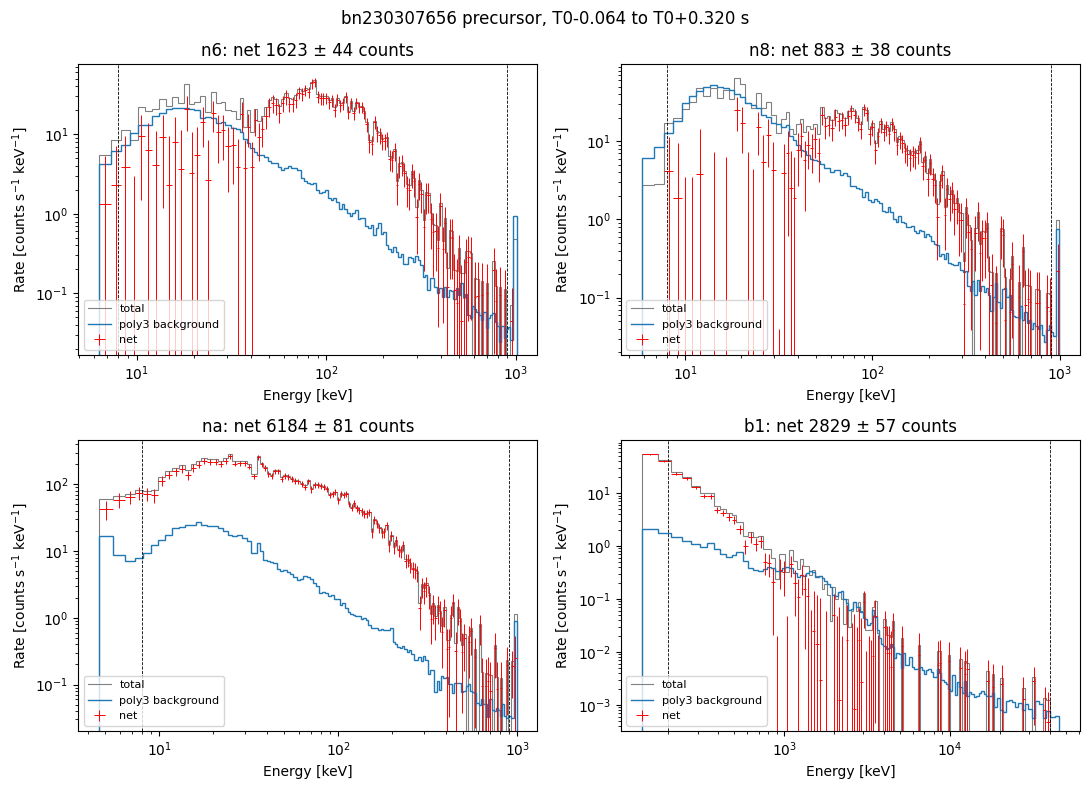

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, det in zip(axes.flat, DETECTORS):
    s = spectra[det]
    lo = np.asarray(responses[det].ebounds.low_edges())
    hi = np.asarray(responses[det].ebounds.high_edges())
    norm = s["live_time"] * (hi - lo)                 # counts -> counts/s/keV
    centre = np.sqrt(lo * hi)
    # Channel 0 and the overflow channel (127) are not real energy bins
    good = np.arange(len(lo))[1:-1]

    ax.stairs((s["src"] / norm)[good], np.append(lo[good], hi[good][-1]),
              color="grey", lw=0.8, label="total")
    ax.stairs((s["bkg"].counts / norm)[good], np.append(lo[good], hi[good][-1]),
              color="tab:blue", lw=1.0, label=f"poly{BKG_ORDER} background")
    ax.errorbar(centre[good], (s["net"] / norm)[good], yerr=(s["net_err"] / norm)[good],
                xerr=[(centre - lo)[good], (hi - centre)[good]],
                fmt="none", ecolor="red", elinewidth=0.7, label="net")
    for edge in FIT_RANGE[det[0]]:
        ax.axvline(edge, color="black", ls="--", lw=0.6)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"{det}: net {s['net'].sum():.0f} ± {np.sqrt(np.sum(s['net_err']**2)):.0f} counts")
    ax.set_xlabel("Energy [keV]")
    ax.set_ylabel("Rate [counts s$^{-1}$ keV$^{-1}$]")
    ax.legend(loc="lower left", fontsize=8)
fig.suptitle(f"{BURST_ID} precursor, T0{PRECURSOR[0]:+.3f} to T0{PRECURSOR[1]:+.3f} s")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "08_precursor_spectra.png", dpi=200)
plt.show()

Effective area of each response (summed over channels) against photon energy, as a check that the
right detectors and DRMs are loaded. na sees the burst down to ~10 keV, but **n6 and n8 have almost no
area below ~40 keV** (the burst is far off their axis and/or the low-energy photons are blocked by the
spacecraft), which matches their net spectra being consistent with zero there. So the 8 keV lower
limit only makes sense for na; for n6 and n8 the fit range should probably start nearer 40–50 keV.
BGO (b1) takes over above ~150 keV.

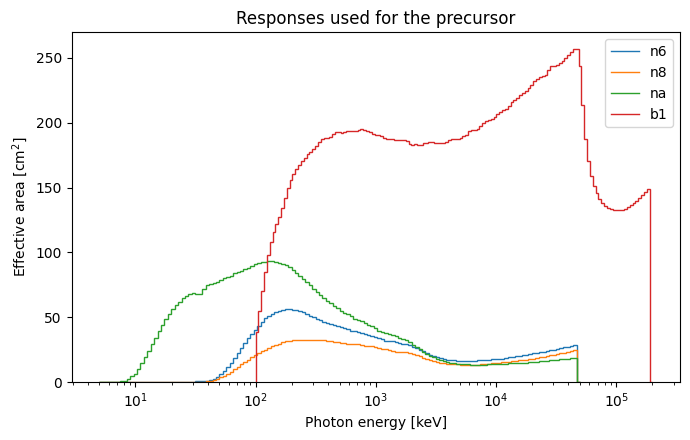

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for det in DETECTORS:
    drm = responses[det].drm
    e_lo, e_hi = np.asarray(drm.photon_bins.low_edges()), np.asarray(drm.photon_bins.high_edges())
    area = np.asarray(drm.matrix).sum(axis=1)          # cm^2, one value per photon bin
    ax.stairs(area, np.append(e_lo, e_hi[-1]), label=det)
ax.set_xscale("log")
ax.set_xlabel("Photon energy [keV]")
ax.set_ylabel("Effective area [cm$^2$]")
ax.set_title("Responses used for the precursor")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "08_precursor_responses.png", dpi=200)
plt.show()

## Save for the fit

One PHA (source), BAK (background) and RSP (response) file per detector in `ignacio/spectra/`,
in the standard OGIP format. The next notebook can reopen them with GDT, and XSPEC can read them
directly as the backup fitter. They can always be regenerated by rerunning this notebook.

In [9]:
for det in DETECTORS:
    s = spectra[det]
    stem = f"{BURST_ID}_{det}_precursor"
    bak = Bak.from_data(s["bkg"], gti=s["pha"].gti, trigger_time=s["pha"].trigtime)
    s["pha"].write(SPECTRUM_DIR, filename=f"{stem}.pha", overwrite=True)
    # rates=True: Bak.open only reads the RATE column, not COUNTS
    bak.write(SPECTRUM_DIR, filename=f"{stem}.bak", rates=True, overwrite=True)
    responses[det].write(SPECTRUM_DIR, filename=f"{stem}.rsp", overwrite=True)
print(sorted(p.name for p in SPECTRUM_DIR.iterdir()))

# Reopen the files to check they round-trip
from gdt.core.pha import Pha
from gdt.missions.fermi.gbm.response import GbmRsp
for det in DETECTORS:
    stem = SPECTRUM_DIR / f"{BURST_ID}_{det}_precursor"
    assert np.allclose(Pha.open(f"{stem}.pha").data.counts, spectra[det]["src"])
    assert np.allclose(Bak.open(f"{stem}.bak").data.counts, spectra[det]["bkg"].counts)
    assert GbmRsp.open(f"{stem}.rsp").num_chans == spectra[det]["pha"].num_chans
print("all files reopen with the same counts")

['bn230307656_b1_precursor.bak', 'bn230307656_b1_precursor.pha', 'bn230307656_b1_precursor.rsp', 'bn230307656_n6_precursor.bak', 'bn230307656_n6_precursor.pha', 'bn230307656_n6_precursor.rsp', 'bn230307656_n8_precursor.bak', 'bn230307656_n8_precursor.pha', 'bn230307656_n8_precursor.rsp', 'bn230307656_na_precursor.bak', 'bn230307656_na_precursor.pha', 'bn230307656_na_precursor.rsp', 'precursor_band_fit.json']
all files reopen with the same counts


## Summary and next step

The four precursor spectra (`spectra[det]["pha"]`, `["bkg"]`) and responses (`responses[det]`) are
the three lists GDT's fitters take. The fit is in `09_precursor_band_fit.ipynb` (Band) and
`10_precursor_flux_and_models.ipynb` (flux, νFν plot, other models).